In [1]:
%load_ext autoreload
%autoreload 2

# Modelos

Seguimos desde el notebook de datos. Ahi vimos que el bloque de no-detecciones y los colores WISE no aportan, y que el periodo hay que pasarlo a log porque si no aplasta al resto.

Acá partimos train / val / test **antes** de imputar y escalar. Despues entrenamos un autoencoder, un GMM en el cuello de botella, y una pasada de MCDSVDD.

In [2]:
%matplotlib inline

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# jupyter a veces parte en notebooks/ y a veces en la raiz
aqui = Path.cwd().resolve()
raiz = aqui if (aqui / "src").exists() else aqui.parent
if str(raiz / "src") not in sys.path:
    sys.path.insert(0, str(raiz / "src"))

from ic_project.modelos import asignar_mcdsvdd, entrenar_autoencoder, entrenar_mcdsvdd, latente
from ic_project.preprocesamiento import preparar_conjuntos

colores = {
    "CEP": "steelblue",
    "DSCT": "chocolate",
    "EB": "mediumseagreen",
    "LPV": "indianred",
    "RRL": "magenta",
}

In [3]:
ruta_datos = raiz / "data" / "raw"

df_features = pd.read_parquet(ruta_datos / "features.parquet")
df_oids = pd.read_parquet(ruta_datos / "oids.parquet")

print("features", df_features.shape)
print("oids    ", df_oids.shape)

X = df_features.drop(columns="oid")
oids = df_features["oid"].reset_index(drop=True)
labels = df_features[["oid"]].merge(df_oids, on="oid", how="left")["alerceclass"].reset_index(drop=True)

mask = labels.notna()
X = X.loc[mask].reset_index(drop=True)
oids = oids.loc[mask].reset_index(drop=True)
labels = labels.loc[mask].reset_index(drop=True)

print(labels.value_counts())

features (8419, 179)
oids     (9829, 2)
alerceclass
EB      2689
RRL     2652
LPV     1374
CEP     1172
DSCT     532
Name: count, dtype: int64


### Particion

70% train, 15% val, 15% test, estratificado por clase. La mediana, el recorte y la escala se calculan solo con train. Si se calculan con todo el conjunto, el test se filtra al modelo.

La escala es z-score: a cada feature se le resta la media y se divide por la desviacion estandar de train. Antes dividiamos por el IQR, pero las features de cola pesada (`Harmonics_mag_*`, `delta_period_*`) quedaban con valores de cientos y se llevaban casi todo el error del autoencoder. Con z-score todas pesan lo mismo.

In [4]:
# solo_periodo_color=False: aca entran las 158 features, no solo las 7 de periodo y color
conjuntos, prep, descartadas = preparar_conjuntos(X, labels, oids, solo_periodo_color=False)

print("descartadas:", len(descartadas))
print(
    "train / val / test:",
    len(conjuntos["y_train"]),
    len(conjuntos["y_val"]),
    len(conjuntos["y_test"]),
)
print("features que entran al modelo:", conjuntos["x_train"].shape[1])
print(conjuntos["y_train"].value_counts())

descartadas: 20
train / val / test: 5893 1263 1263
features que entran al modelo: 158
alerceclass
EB      1883
RRL     1856
LPV      962
CEP      820
DSCT     372
Name: count, dtype: int64


### Autoencoder

Comprime las features a 8 numeros y trata de reconstruirlas. Esos 8 son el cuello de botella. Con 2 se pierde harto, asi que el grafico de mas abajo es un UMAP del test, igual que en el notebook de datos. El UMAP es solo para mirar, no entra al GMM.

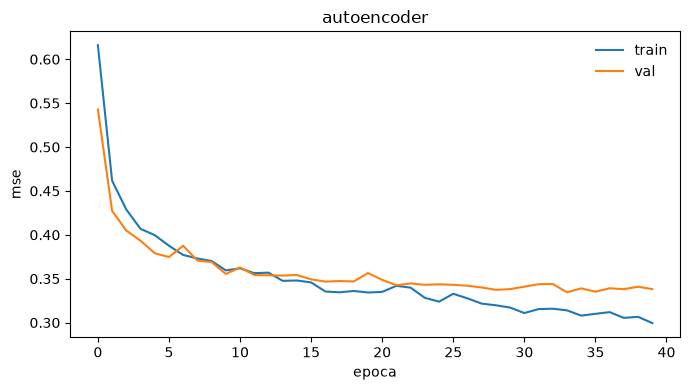

epocas corridas: 40
mejor mse val: 0.3345


In [5]:
ae, hist = entrenar_autoencoder(
    conjuntos["x_train"],
    conjuntos["x_val"],
    z_dim=8,
    n_epocas=40,
    semilla=42,
)

plt.figure(figsize=(7, 4))
plt.plot(hist.train, label="train")
plt.plot(hist.val, label="val")
plt.xlabel("epoca")
plt.ylabel("mse")
plt.legend(frameon=False)
plt.title("autoencoder")
plt.tight_layout()
plt.show()

print("epocas corridas:", len(hist.val))
print("mejor mse val:", round(min(hist.val), 4))

C:\Users\fonse\Desktop\Universidad\Inteligencia\Proyecto\Git-proyecto\alerce-meeting2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\fonse\Desktop\Universidad\Inteligencia\Proyecto\Git-proyecto\alerce-meeting2\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


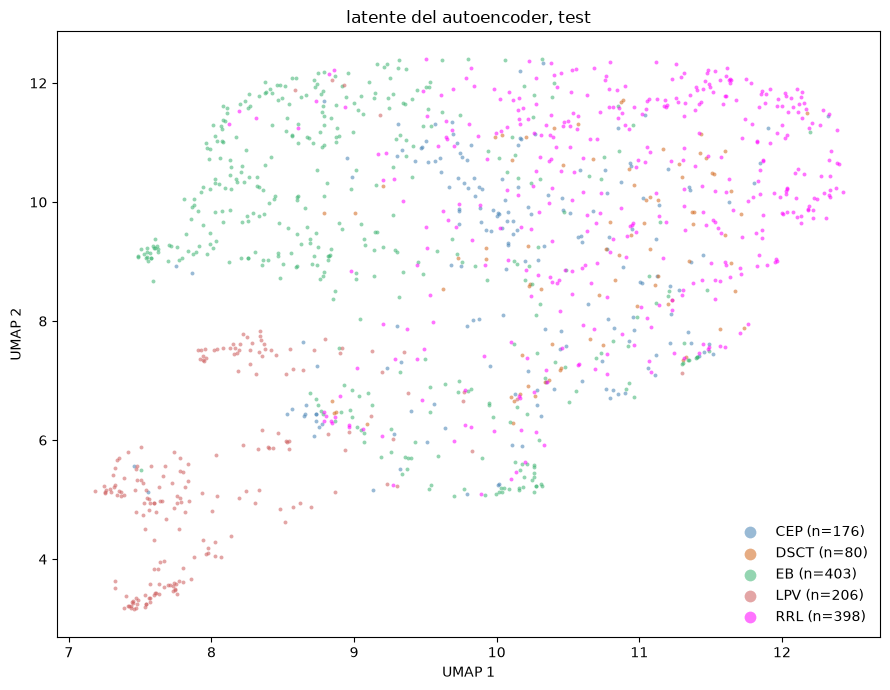

In [6]:
import umap

z_train = latente(ae, conjuntos["x_train"])
z_test = latente(ae, conjuntos["x_test"])

# UMAP solo del test, para dibujar
emb = umap.UMAP(n_neighbors=50, min_dist=0.1, n_components=2, random_state=42).fit_transform(z_test)

clases_test = conjuntos["y_test"].to_numpy()

fig, ax = plt.subplots(figsize=(9, 7))
for clase, color in colores.items():
    m = clases_test == clase
    ax.scatter(emb[m, 0], emb[m, 1], s=8, alpha=0.55, c=color, label=f"{clase} (n={m.sum()})", linewidths=0)

ax.legend(markerscale=3, frameon=False)
ax.set_title("latente del autoencoder, test")
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
plt.tight_layout()
plt.show()

El MSE de validacion queda en 0.33. Como cada feature tiene varianza 1, eso es un tercio de la varianza sin reconstruir usando solo 8 numeros.

LPV queda aparte. EB y RRL se van a lados distintos pero se tocan, y CEP y DSCT quedan repartidas entre las dos. Un clustering que no ve la etiqueta puede recuperar LPV, pero no tiene de donde sacar las 5 clases.

### GMM

Mezcla de gaussianas con 5 componentes, ajustada **solo** con el latente de train. Las metricas son del test.

Silhouette mas alto = grupos mas separados. Davies-Bouldin mas bajo = mejor. Esas dos las calculamos con los clusters del GMM y tambien con las clases reales (no miden lo mismo). ARI y NMI comparan clusters contra clase: 0 es azar, 1 es que coinciden.

In [7]:
from sklearn.metrics import (
    adjusted_rand_score,
    davies_bouldin_score,
    normalized_mutual_info_score,
    silhouette_score,
)
from sklearn.mixture import GaussianMixture


def medir(z, pred, real):
    print("silhouette grupos ", round(silhouette_score(z, pred), 3))
    print("silhouette clases ", round(silhouette_score(z, real), 3))
    print("davies-bouldin grupos", round(davies_bouldin_score(z, pred), 3))
    print("davies-bouldin clases", round(davies_bouldin_score(z, real), 3))
    print("ARI", round(adjusted_rand_score(real, pred), 3))
    print("NMI", round(normalized_mutual_info_score(real, pred), 3))


gmm = GaussianMixture(n_components=5, covariance_type="full", random_state=42, n_init=5)
gmm.fit(z_train)
pred_gmm = gmm.predict(z_test)

print("GMM en test")
medir(z_test, pred_gmm, clases_test)
print()
display(pd.crosstab(clases_test, pred_gmm, rownames=["clase"], colnames=["cluster"]))

GMM en test
silhouette grupos  0.079
silhouette clases  -0.016
davies-bouldin grupos 2.726
davies-bouldin clases 3.617
ARI 0.201
NMI 0.263



cluster,0,1,2,3,4
clase,,,,,
CEP,3,78,3,40,52
DSCT,0,15,0,17,48
EB,0,161,24,77,141
LPV,71,11,102,21,1
RRL,0,49,0,43,306


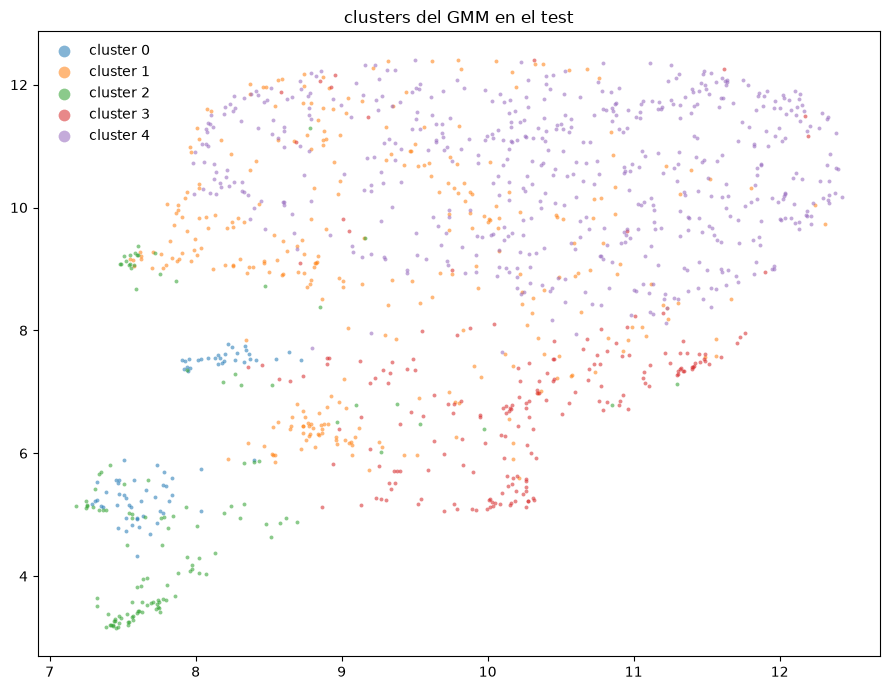

In [8]:
# mismos ejes que el UMAP de arriba, ahora pintado por cluster
fig, ax = plt.subplots(figsize=(9, 7))
for k in np.unique(pred_gmm):
    m = pred_gmm == k
    ax.scatter(emb[m, 0], emb[m, 1], s=8, alpha=0.55, label=f"cluster {k}", linewidths=0)
ax.legend(markerscale=3, frameon=False)
ax.set_title("clusters del GMM en el test")
plt.tight_layout()
plt.show()

El GMM no ve la clase. En la tabla se nota que LPV es la unica que recupera: 173 de 206 caen en dos componentes donde casi no hay otra cosa. El resto va mezclado: un componente junta a la mayoria de RRL con harto EB y DSCT, y CEP queda repartida. El ARI es 0.20, o sea recupera poco de las etiquetas. Calza con el UMAP de arriba.

### MCDSVDD

Este si usa la clase. Parte del encoder que ya entrenamos, calcula un centro por clase y acerca cada objeto al centro de la suya. En test lo asignamos al centro mas cercano.

DSCT tiene harto menos objetos que EB y RRL, y la perdida promedia todos los objetos por igual, asi que las clases chicas pesan poco. Para compensarlo, al entrenar repetimos objetos de cada clase hasta igualar a la mas grande. Es solo en train: val y test quedan con sus proporciones reales.

objetos por clase en train: {'CEP': 820, 'DSCT': 372, 'EB': 1883, 'LPV': 962, 'RRL': 1856}
al entrenar: 1883 por clase, 9415 en total


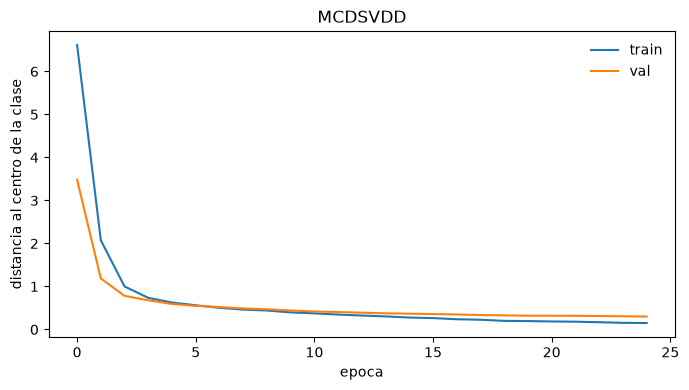

epocas: 25


In [9]:
clases = sorted(conjuntos["y_train"].unique())
mapa = {c: i for i, c in enumerate(clases)}

y_train_i = conjuntos["y_train"].map(mapa).to_numpy()
y_val_i = conjuntos["y_val"].map(mapa).to_numpy()

# sobremuestreo: cada clase entra tantas veces como la mas grande, repitiendo objetos de las chicas.
# es solo para entrenar; val y test quedan con sus proporciones reales
rng = np.random.default_rng(42)
por_clase = [np.flatnonzero(y_train_i == k) for k in range(len(clases))]
n_max = max(len(ix) for ix in por_clase)
balanceado = np.concatenate([rng.choice(ix, size=n_max, replace=len(ix) < n_max) for ix in por_clase])
print("objetos por clase en train:", dict(zip(clases, map(len, por_clase))))
print("al entrenar:", n_max, "por clase,", len(balanceado), "en total")

mcd, hist_mcd = entrenar_mcdsvdd(
    conjuntos["x_train"][balanceado],
    y_train_i[balanceado],
    conjuntos["x_val"],
    y_val_i,
    autoencoder=ae,
    z_dim=8,
    n_epocas=25,
    semilla=42,
)

plt.figure(figsize=(7, 4))
plt.plot(hist_mcd.train, label="train")
plt.plot(hist_mcd.val, label="val")
plt.xlabel("epoca")
plt.ylabel("distancia al centro de la clase")
plt.legend(frameon=False)
plt.title("MCDSVDD")
plt.tight_layout()
plt.show()

print("epocas:", len(hist_mcd.val))

C:\Users\fonse\Desktop\Universidad\Inteligencia\Proyecto\Git-proyecto\alerce-meeting2\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


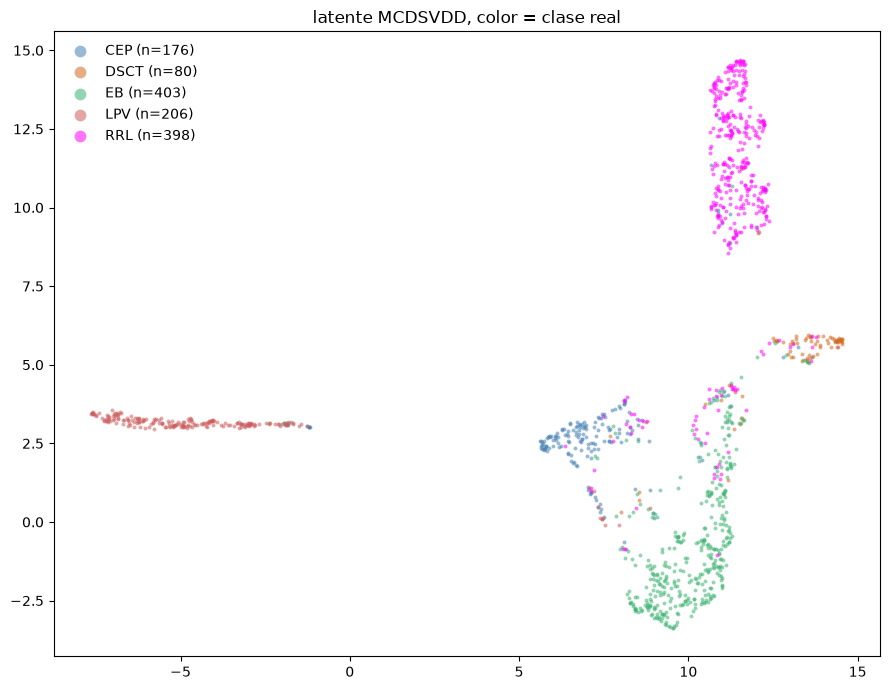

MCDSVDD en test
silhouette grupos  0.602
silhouette clases  0.495
davies-bouldin grupos 0.61
davies-bouldin clases 0.759
ARI 0.731
NMI 0.669



centro,CEP,DSCT,EB,LPV,RRL
clase,,,,,
CEP,148,3,10,5,10
DSCT,5,63,5,0,7
EB,16,10,364,3,10
LPV,5,1,6,193,1
RRL,30,14,14,0,340


In [10]:
z_mcd = latente(mcd, conjuntos["x_test"])
pred_i = asignar_mcdsvdd(mcd, conjuntos["x_test"])
pred_mcd = np.array(clases)[pred_i]

emb_mcd = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42).fit_transform(z_mcd)

fig, ax = plt.subplots(figsize=(9, 7))
for clase, color in colores.items():
    m = clases_test == clase
    ax.scatter(emb_mcd[m, 0], emb_mcd[m, 1], s=8, alpha=0.55, c=color, label=f"{clase} (n={m.sum()})", linewidths=0)
ax.legend(markerscale=3, frameon=False)
ax.set_title("latente MCDSVDD, color = clase real")
plt.tight_layout()
plt.show()

print("MCDSVDD en test")
medir(z_mcd, pred_mcd, clases_test)
print()
display(pd.crosstab(clases_test, pred_mcd, rownames=["clase"], colnames=["centro"]))

Mejora harto respecto al GMM (ARI 0.73 contra 0.20) porque ahora el modelo si vio la clase al entrenar. En la diagonal de la tabla estan los que caen en su propio centro, y las cinco clases quedan mayormente en el suyo.

El sobremuestreo se nota en DSCT: 63 de 80 caen en su centro. Lo que mas se confunde ahora es RRL, con 30 objetos que se van a CEP y 14 a DSCT.

### Que features importan

Random forest solo con train, con peso para las clases chicas. Los hiperparametros los elige `RandomizedSearchCV`: 20 combinaciones al azar, validacion cruzada de 3 folds dentro de train y F1 macro como metrica. No lo usamos para filtrar el autoencoder, es para ver si el periodo queda arriba.


mejores hiperparametros: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 16}
f1 macro en validacion cruzada: 0.912
f1 macro en val: 0.923


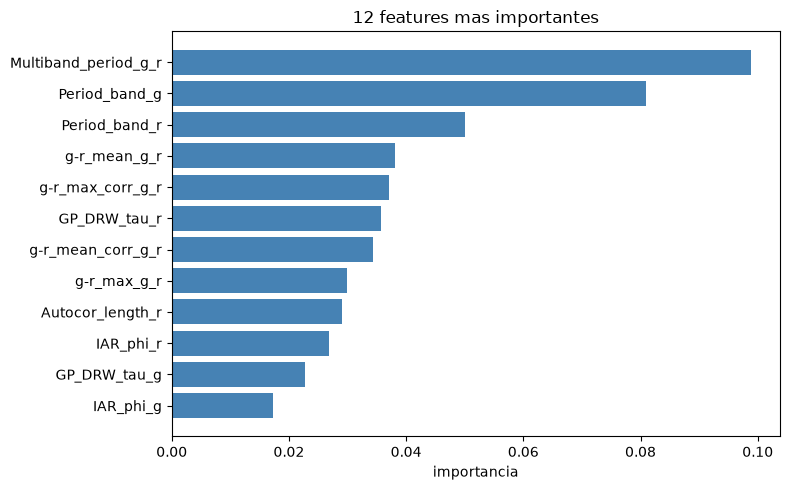

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

# valores entre los que sortea la busqueda
espacio = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [8, 12, 16, 24, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", 0.2],
}

busqueda = RandomizedSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1),
    param_distributions=espacio,
    n_iter=20,
    scoring="f1_macro",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    random_state=42,
)
# 20 combinaciones x 3 folds, se demora un par de minutos
busqueda.fit(conjuntos["x_train"], conjuntos["y_train"])

# el mejor queda reentrenado con todo train
rf = busqueda.best_estimator_
pred_val = rf.predict(conjuntos["x_val"])

print("mejores hiperparametros:", busqueda.best_params_)
print("f1 macro en validacion cruzada:", round(busqueda.best_score_, 3))
print("f1 macro en val:", round(f1_score(conjuntos["y_val"], pred_val, average="macro"), 3))

imp = pd.Series(rf.feature_importances_, index=prep.columnas_).sort_values(ascending=False)
top = imp.head(12)[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top.index, top.values, color="steelblue")
plt.xlabel("importancia")
plt.title("12 features mas importantes")
plt.tight_layout()
plt.show()

Las primeras son periodos (multibanda, banda g, banda r) y despues el color g-r. Era lo que esperabamos: las clases viven en escalas de tiempo distintas.

Queda por ver si estuvo bien descartar las 20 features de los dos bloques con mas datos faltantes, las no-detecciones y los colores WISE. Para eso entrenamos el mismo random forest con las 178, sin botar nada, y cruzamos la importancia de cada feature con su % de NaN. Este modelo es solo para mirar: el resto del notebook sigue con las 158.

f1 macro en val, 158 features: 0.923
f1 macro en val, 178 features: 0.924
correlacion de Spearman entre % NaN e importancia: -0.081


,n,nan_medio,importancia_total,mejor_puesto,peor_puesto
bloque,,,,,
WISE,6,19.8,0.101,8,38
en el modelo,158,6.2,0.885,1,178
no-detecciones,14,33.3,0.014,127,169


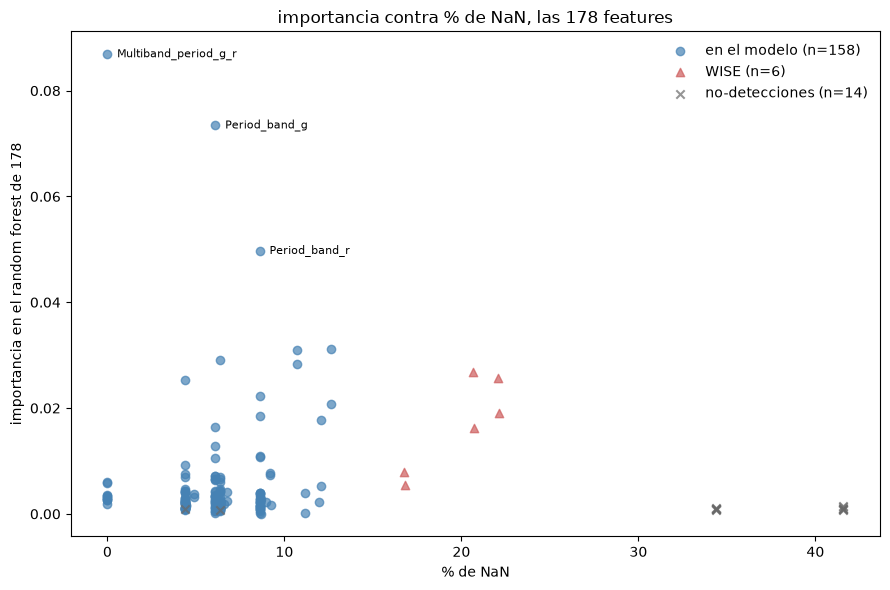

In [12]:
from sklearn.base import clone

from ic_project.preprocesamiento import (
    Preprocesador,
    aplicar_transformaciones_elemento,
    especificar_transformaciones,
    particionar,
)

# los mismos pasos de preparar_conjuntos, pero sin botar las 20 columnas
partes = particionar(X, labels, oids)
assert (partes["oid_train"] == conjuntos["oid_train"]).all()  # mismos objetos en train

spec = especificar_transformaciones(partes["x_train"])
x_train_178 = aplicar_transformaciones_elemento(partes["x_train"], spec)
x_val_178 = aplicar_transformaciones_elemento(partes["x_val"], spec)
prep_178 = Preprocesador().ajustar(x_train_178)

# clone copia los hiperparametros de rf y deja el modelo sin entrenar
rf_178 = clone(rf)
rf_178.fit(prep_178.transformar(x_train_178).to_numpy(dtype=np.float32), partes["y_train"])
pred_val_178 = rf_178.predict(prep_178.transformar(x_val_178).to_numpy(dtype=np.float32))

print("f1 macro en val, 158 features:", round(f1_score(conjuntos["y_val"], pred_val, average="macro"), 3))
print("f1 macro en val, 178 features:", round(f1_score(partes["y_val"], pred_val_178, average="macro"), 3))

# una fila por feature: cuanto NaN tiene, cuanto importa y a que bloque pertenece
comp = pd.DataFrame(
    {
        "pct_nan": X.isna().mean() * 100,
        "importancia": pd.Series(rf_178.feature_importances_, index=prep_178.columnas_),
    }
)
comp["puesto"] = comp["importancia"].rank(ascending=False, method="min").astype(int)
comp["bloque"] = "en el modelo"
comp.loc[comp.index.isin(descartadas), "bloque"] = "no-detecciones"
comp.loc[comp.index.isin(descartadas) & comp.index.str.contains("W1|W2|W3"), "bloque"] = "WISE"

print(
    "correlacion de Spearman entre % NaN e importancia:",
    round(comp["pct_nan"].corr(comp["importancia"], method="spearman"), 3),
)
display(
    comp.groupby("bloque")
    .agg(
        n=("pct_nan", "size"),
        nan_medio=("pct_nan", "mean"),
        importancia_total=("importancia", "sum"),
        mejor_puesto=("puesto", "min"),
        peor_puesto=("puesto", "max"),
    )
    .round({"nan_medio": 1, "importancia_total": 3})
)

estilo = {
    "en el modelo": ("steelblue", "o"),
    "WISE": ("indianred", "^"),
    "no-detecciones": ("dimgray", "x"),
}
fig, ax = plt.subplots(figsize=(9, 6))
for bloque, (color, marca) in estilo.items():
    sub = comp[comp["bloque"] == bloque]
    ax.scatter(sub["pct_nan"], sub["importancia"], s=36, alpha=0.7, c=color, marker=marca, label=f"{bloque} (n={len(sub)})")

# nombre solo a los tres periodos, el resto se lee por bloque
for nombre in ["Multiband_period_g_r", "Period_band_g", "Period_band_r"]:
    ax.annotate(
        nombre,
        (comp.loc[nombre, "pct_nan"], comp.loc[nombre, "importancia"]),
        xytext=(7, 0),
        textcoords="offset points",
        va="center",
        fontsize=8,
    )

ax.set_xlabel("% de NaN")
ax.set_ylabel("importancia en el random forest de 178")
ax.set_title("importancia contra % de NaN, las 178 features")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

- **No hay relacion entre datos faltantes e importancia.** La correlacion de Spearman es -0.08. Lo que importa es el bloque.
- **Las no-detecciones quedan al fondo.** Son las que mas NaN tienen (33% en promedio) y entre las 14 suman 1.4% de la importancia. Descartarlas no cuesta nada.
- **Los colores WISE si tienen señal, pero no hacen falta.** Quedan desde el puesto 8 y suman cerca del 10% de la importancia. Aun asi el F1 macro en val no cambia (0.923 con 158 y 0.924 con 178), y usarlos obliga a imputar un quinto de los objetos.

Por eso seguimos con las 158.

## Analisis cualitativo

Hasta aca medimos los modelos con numeros. Ahora miramos objetos de test: los prototipos, que son los mas cercanos al centro de cada grupo, y los outliers, que son los que quedan mas afuera. Lo hacemos para el GMM y para MCDSVDD.

Las curvas de luz salen de `lcs.parquet`. Sacamos las detecciones sin corregir (`corrected`), las dudosas (`dubious`) y las que traen magnitud 100, que es un relleno. Para plegar usamos el periodo multibanda, el mismo que entra a los modelos.

En los graficos verde es la banda g y rojo la banda r. El eje vertical es magnitud, con lo mas brillante arriba.

In [13]:
from ic_project.visualizacion import fase_plegada

lcs = pd.read_parquet(
    ruta_datos / "lcs.parquet",
    columns=["oid", "mjd", "fid", "magpsf_corr", "corrected", "dubious"],
    filters=[("oid", "in", list(conjuntos["oid_test"]))],
)
limpias = lcs[lcs["corrected"] & ~lcs["dubious"] & (lcs["magpsf_corr"] < 30)]
curvas = dict(tuple(limpias.groupby("oid")))
print("detecciones de test:", len(lcs), "| limpias:", len(limpias))

# una fila por objeto de test
crudo = X.set_index(oids).loc[conjuntos["oid_test"]]
cols_g = [c for c in prep.columnas_ if c.endswith("_g")]
cols_r = [c for c in prep.columnas_ if c.endswith("_r") and not c.endswith("_g_r")]

obj = pd.DataFrame(
    {
        "oid": conjuntos["oid_test"].to_numpy(),
        "clase": clases_test,
        "periodo": conjuntos["periodo_test"].to_numpy(),
        "detecciones": limpias.groupby("oid").size().reindex(conjuntos["oid_test"], fill_value=0).to_numpy(),
        # le faltan todas las features de la banda g o todas las de la banda r
        "sin_una_banda": (crudo[cols_g].isna().all(axis=1) | crudo[cols_r].isna().all(axis=1)).to_numpy(),
        "componente_gmm": pred_gmm,
        "centro_mcdsvdd": pred_mcd,
    }
)

bandas = {1: "tab:green", 2: "tab:red"}


def dibujar_curva(ax, oid, titulo, periodo=None):
    """Sin periodo dibuja magnitud contra tiempo. Con periodo, la curva plegada en dos ciclos."""
    sub = curvas.get(oid)
    if sub is None:
        ax.text(0.5, 0.5, "sin detecciones limpias", ha="center", va="center", transform=ax.transAxes, fontsize=8)
    else:
        for fid, color in bandas.items():
            b = sub[sub["fid"] == fid]
            mag = b["magpsf_corr"].to_numpy()
            if periodo is None:
                ax.scatter(b["mjd"], mag, s=4, alpha=0.5, c=color, linewidths=0)
            else:
                fase = fase_plegada(b["mjd"].to_numpy(), float(periodo))
                ax.scatter(np.r_[fase, fase + 1], np.tile(mag, 2), s=4, alpha=0.5, c=color, linewidths=0)
        ax.invert_yaxis()
    ax.set_title(titulo, fontsize=8)
    ax.tick_params(labelsize=7)


def ver_prototipos(grupos):
    """`grupos` es {nombre del grupo: posiciones en test de sus prototipos}. Una fila por grupo."""
    fig, axes = plt.subplots(len(grupos), 3, figsize=(12, 2.6 * len(grupos)), layout="constrained")
    for fila_ax, (nombre, posiciones) in zip(axes, grupos.items()):
        for ax, i in zip(fila_ax, posiciones):
            o = obj.iloc[i]
            dibujar_curva(ax, o["oid"], f"{nombre} | clase {o['clase']} | P = {o['periodo']:.4g} d", periodo=o["periodo"])
    fig.supxlabel("fase")
    fig.supylabel("magnitud")
    plt.show()


def ver_outliers(posiciones, puntaje, nombre):
    """Tabla y curvas de los outliers: a la izquierda en el tiempo, a la derecha plegada."""
    tabla = obj.iloc[posiciones].copy()
    tabla[nombre] = puntaje[posiciones]
    display(tabla.round({"periodo": 4, nombre: 1}).reset_index(drop=True))

    fig, axes = plt.subplots(len(posiciones), 2, figsize=(11, 2.5 * len(posiciones)), layout="constrained")
    for (ax_t, ax_p), i in zip(axes, posiciones):
        o = obj.iloc[i]
        dibujar_curva(ax_t, o["oid"], f"{o['oid']} | clase {o['clase']} | {nombre} {puntaje[i]:.1f}")
        dibujar_curva(ax_p, o["oid"], f"plegada con P = {o['periodo']:.4g} d", periodo=o["periodo"])
    axes[-1, 0].set_xlabel("mjd")
    axes[-1, 1].set_xlabel("fase")
    fig.supylabel("magnitud")
    plt.show()

detecciones de test: 750509 | limpias: 739571


### GMM: prototipos

Los tres objetos mas cercanos al centro de cada componente, entre los que el GMM asigna a ese componente. La cercania es la distancia de Mahalanobis, que usa la covarianza del componente y es la que usa el GMM por dentro.

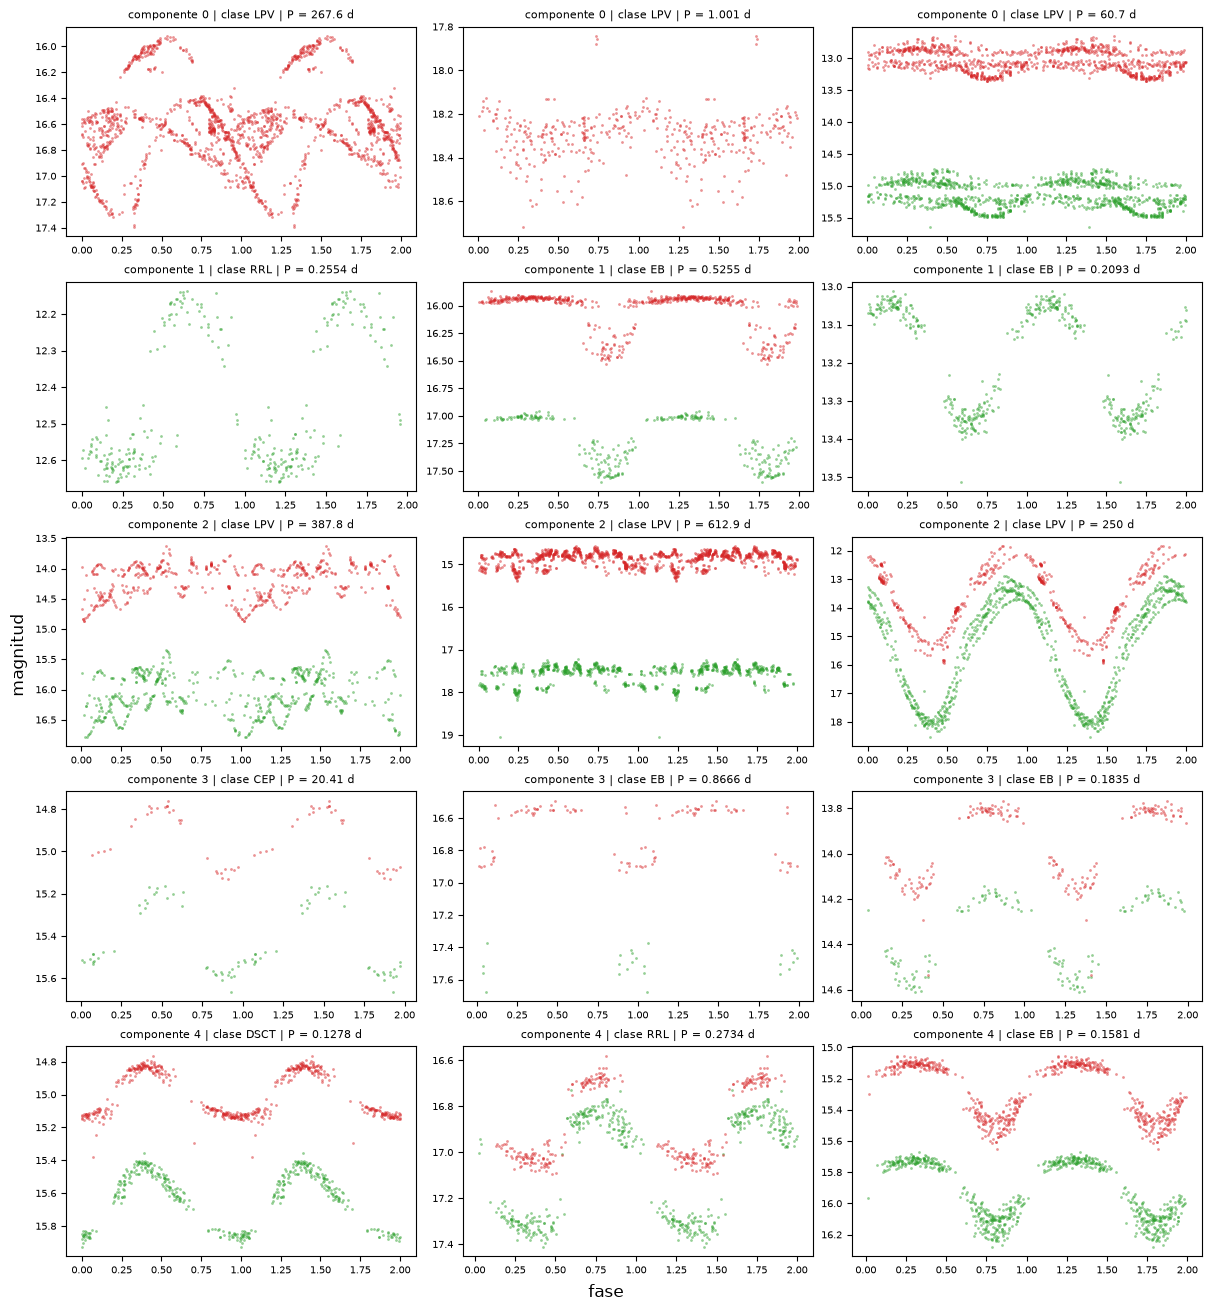

In [14]:
def mahalanobis2(z, modelo, k):
    d = z - modelo.means_[k]
    return np.einsum("ij,jk,ik->i", d, modelo.precisions_[k], d)


protos_gmm = {}
for k in range(gmm.n_components):
    del_k = np.flatnonzero(pred_gmm == k)
    protos_gmm[f"componente {k}"] = del_k[np.argsort(mahalanobis2(z_test[del_k], gmm, k))[:3]]

ver_prototipos(protos_gmm)

Cada fila es un componente. Se ve que el GMM no agrupa solo por clase:

- **Componentes 0 y 2**: son LPV. El 2 tiene las de amplitud grande y periodo largo. El 0 tiene las de amplitud chica.
- **Componente 4**: una DSCT, una RRL y una EB, con periodos de 0.13 a 0.27 dias. Para el GMM son lo mismo, aunque sean tres clases.
- **Componentes 1 y 3**: periodo corto tambien, pero con curvas peor muestreadas: pocos puntos o una sola banda.

### GMM: outliers

Los 6 objetos de test con menor verosimilitud. A la izquierda la curva en el tiempo y a la derecha plegada.


,oid,clase,periodo,detecciones,sin_una_banda,componente_gmm,centro_mcdsvdd,loglik
0,ZTF18abskwur,CEP,18.7747,44,False,2,CEP,-22.7
1,ZTF18abfxrti,LPV,1.0007,17,False,2,CEP,-22.6
2,ZTF18abcqewa,LPV,351.8518,928,False,2,LPV,-22.5
3,ZTF18aborpmv,LPV,487.1795,589,False,2,LPV,-22.2
4,ZTF18aaxddqq,LPV,0.9940,273,False,2,LPV,-22.1
5,ZTF18aaywfxv,LPV,0.9987,2585,False,2,LPV,-22.1


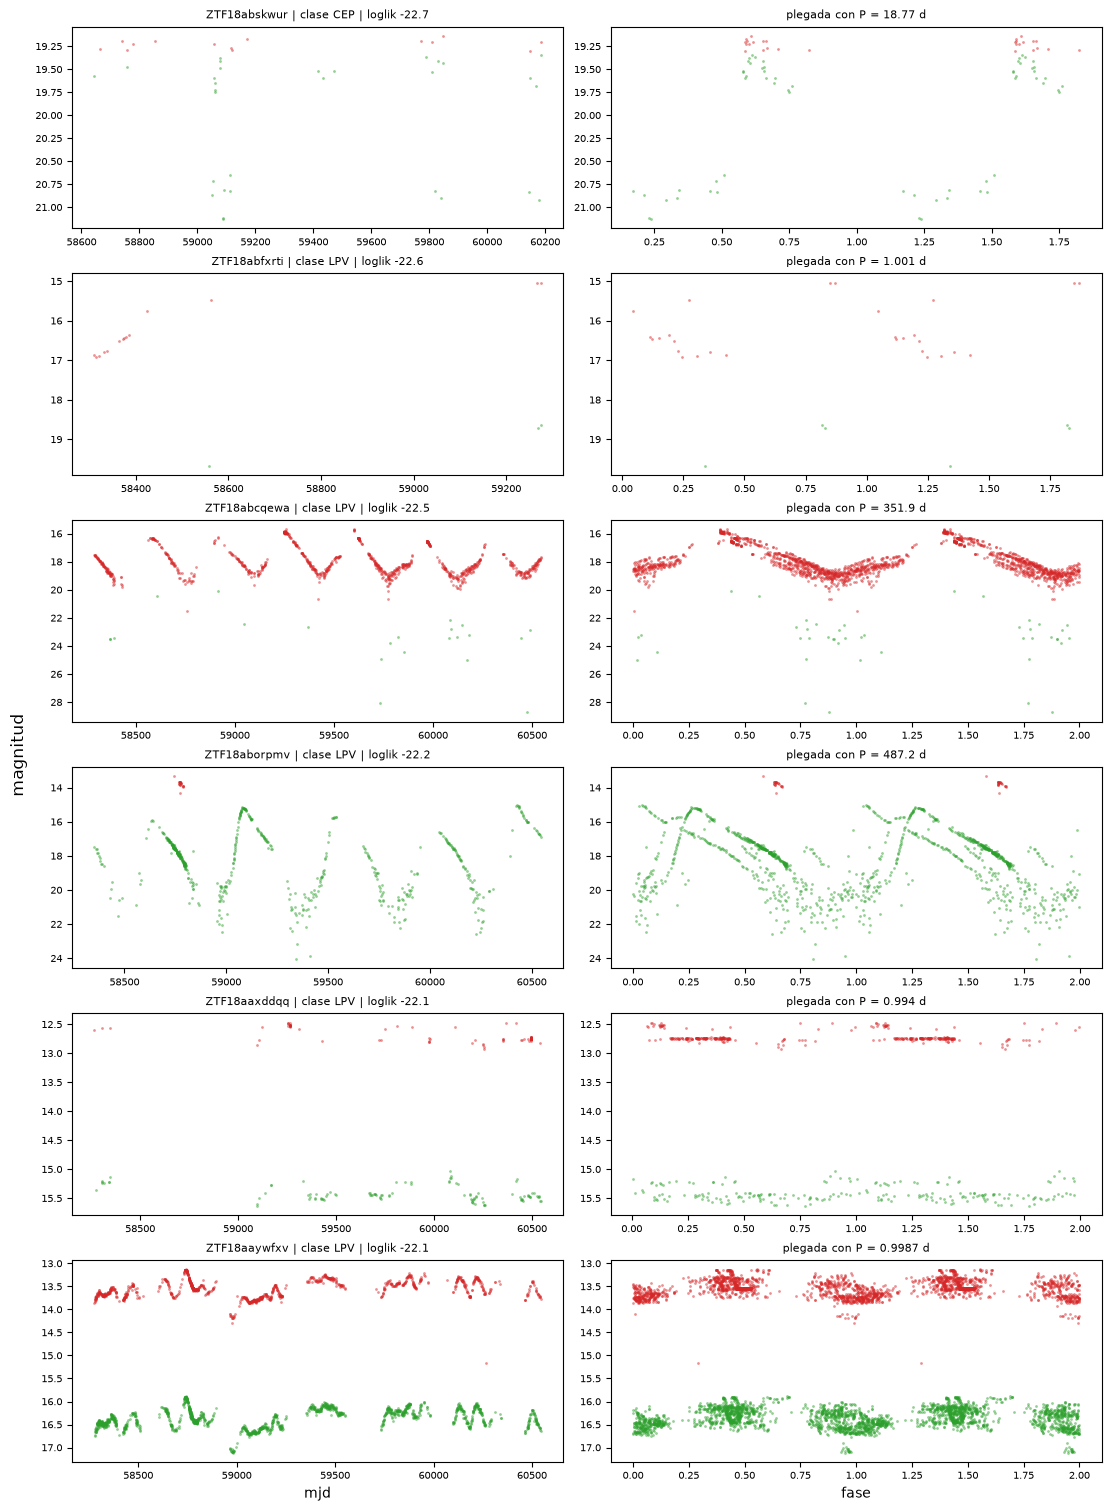

In [15]:
loglik = gmm.score_samples(z_test).astype(float)
ver_outliers(np.argsort(loglik)[:6], loglik, "loglik")

Cinco de los seis son LPV, y los seis caen en el componente 2.

### MCDSVDD: prototipos

Los tres objetos mas cercanos a cada centro de clase, entre los que quedan asignados a ese centro. Aca la distancia es la euclidiana en el latente, que es la que entrena MCDSVDD.


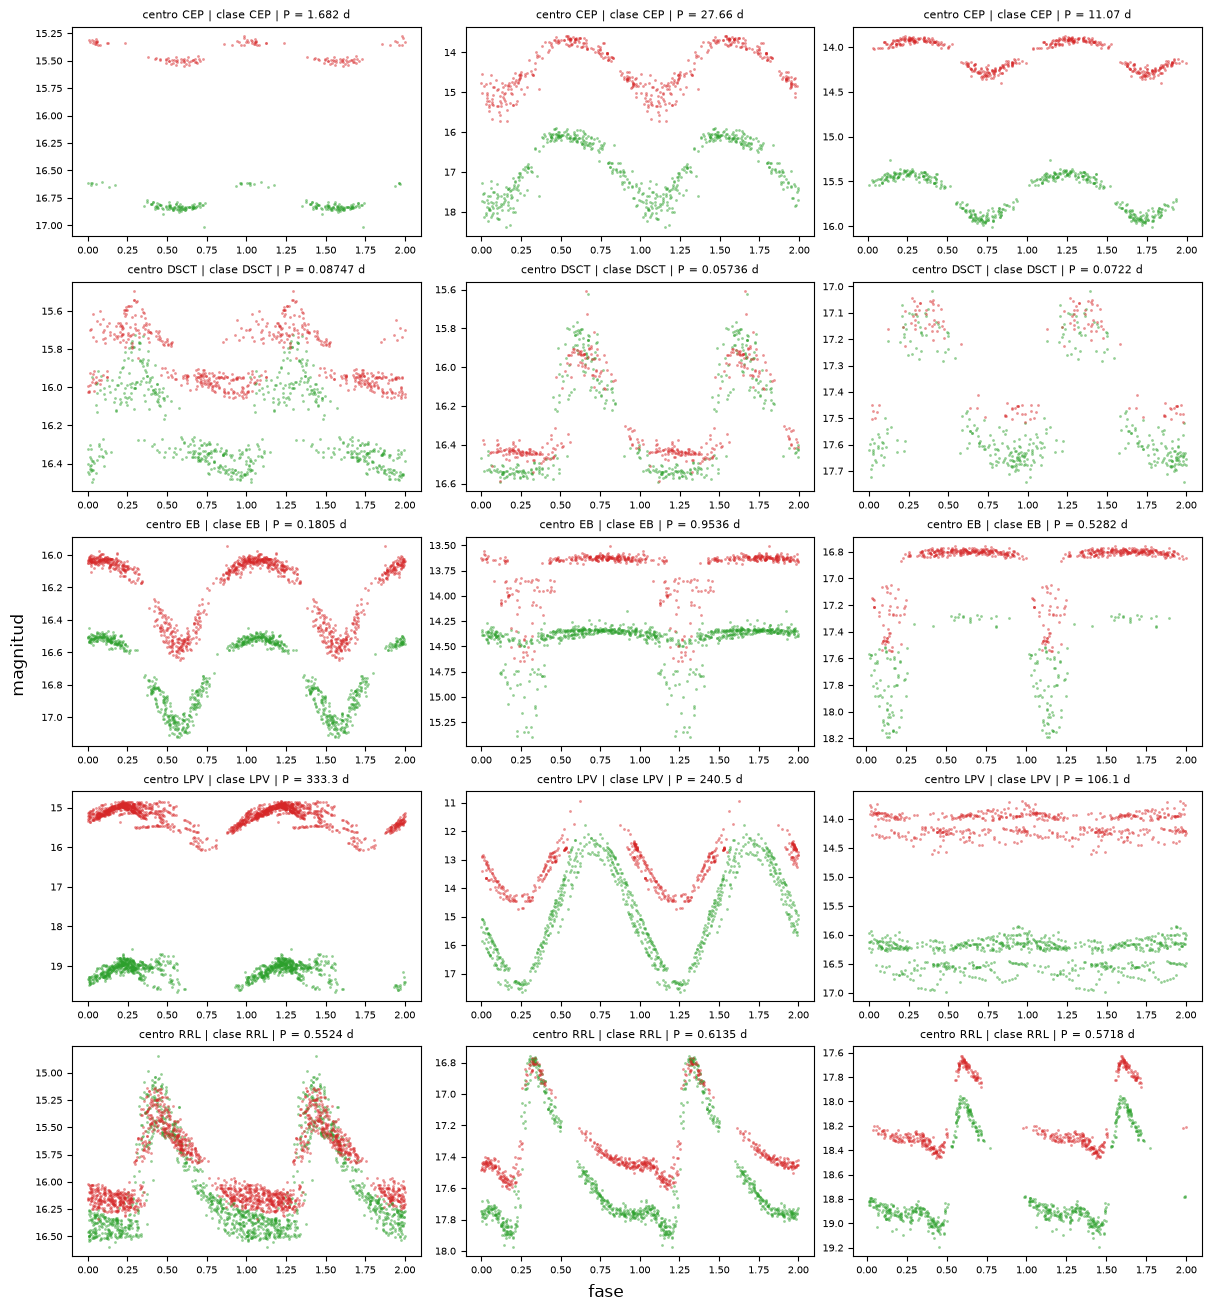

In [16]:
# distancia de cada objeto de test a cada centro, en el latente de MCDSVDD
centros = mcd.centros.detach().cpu().numpy()
dist_centros = np.sqrt(((z_mcd[:, None, :] - centros[None, :, :]) ** 2).sum(axis=2))

protos_mcd = {}
for k, clase in enumerate(clases):
    del_k = np.flatnonzero(pred_i == k)
    protos_mcd[f"centro {clase}"] = del_k[np.argsort(dist_centros[del_k, k])[:3]]

ver_prototipos(protos_mcd)

Los 15 prototipos son de la clase de su centro.

Comparado con el GMM, aca cada grupo si corresponde a una clase, porque el modelo la vio al entrenar.

### MCDSVDD: outliers

Los 6 objetos de test mas lejos de su centro mas cercano.


,oid,clase,periodo,detecciones,sin_una_banda,componente_gmm,centro_mcdsvdd,distancia
0,ZTF18aazmoup,LPV,0.0890,25,True,3,LPV,1.7
1,ZTF18aazetib,CEP,0.2127,56,False,3,LPV,1.7
2,ZTF18abfxrti,LPV,1.0007,17,False,2,CEP,1.7
3,ZTF18abmefly,LPV,0.3338,310,False,2,LPV,1.7
4,ZTF18aayheiu,CEP,0.7861,28,False,3,CEP,1.6
5,ZTF19aazrkxz,LPV,0.9969,109,True,3,EB,1.6


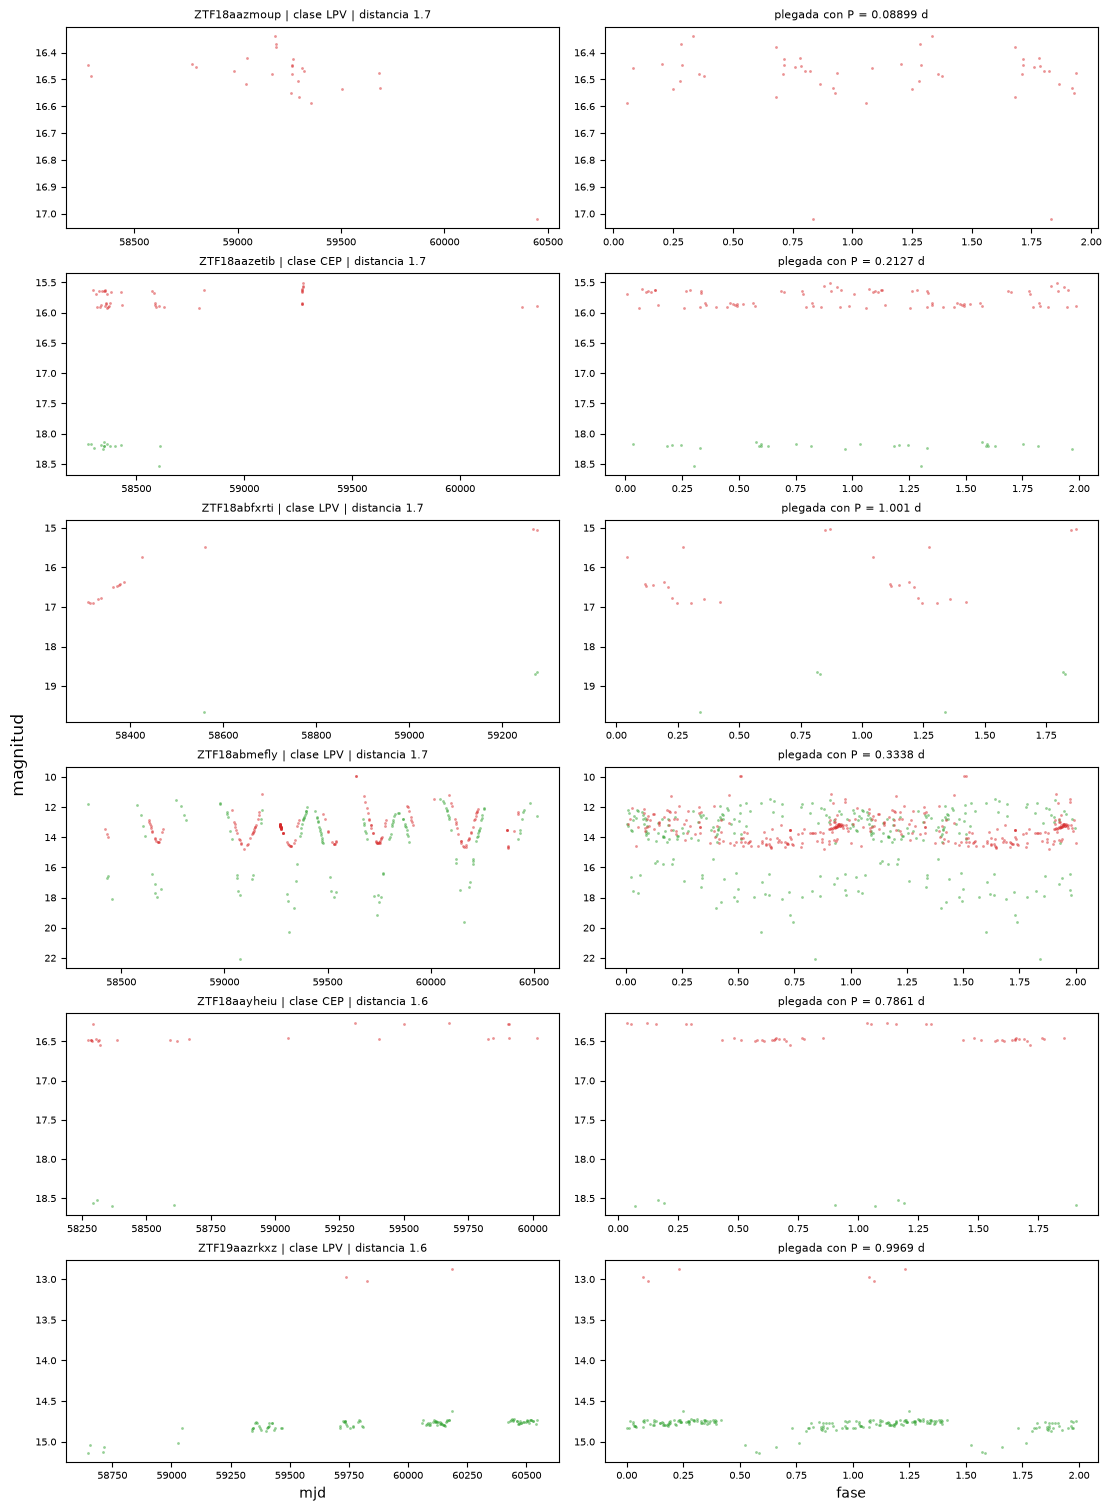

In [17]:
distancia = dist_centros.min(axis=1)
ver_outliers(np.argsort(distancia)[::-1][:6], distancia, "distancia")

Cuatro de los seis tienen entre 17 y 56 detecciones, y a dos les falta una banda completa.

Los cuatro que son LPV tienen periodos de 1 dia o menos (0.09, 0.33 y dos de 1.00).

`ZTF18abfxrti` tambien aparece entre los outliers del GMM. Los otros cinco no.

### Resumen

- **Prototipos.** En MCDSVDD cada centro cae en su clase. En el GMM los componentes mezclan clases: separa las LPV, pero junta DSCT, RRL y EB de periodo corto.
- **Outliers.** El GMM marca sobre todo LPV. MCDSVDD marca objetos con pocas detecciones.

### Pendiente

Pertenencia a mas de un componente y sub-clusters dentro de cada clase. Ya estan hechos para el GMM en `meeting2_completo.ipynb`. Tambien falta el experimento de sacar una clase del entrenamiento para ver si el modelo la marca como rara.
